# Balanced-Subset Robustness

This notebook evaluates whether class imbalance drives the supervised results. It fixes a 153-address cohort with 51 active addresses per class, repeats the supervised comparisons on that cohort, and compares the estimates with the full 436-address analysis. Repeated balanced Node2Vec clustering remains in `03_unsupervised/node2vec.ipynb`.

## Setup and execution mode

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "00_data_graph").exists() and (candidate / "06_robustness_audit").exists():
            return candidate
    raise FileNotFoundError("Project root could not be located")


ROOT = find_project_root(Path.cwd().resolve())
MODULE_DIR = ROOT / "06_robustness_audit" / "01_balanced_subset"
RERUN_DIR = MODULE_DIR / "rerun_validation"
RUN_RETRAINING = False

print(f"Project root: {ROOT}")
print(f"Frozen evidence: {MODULE_DIR}")
print(f"Full rerun enabled: {RUN_RETRAINING}")


Project root: E:\dissertation
Frozen evidence: E:\dissertation\06_robustness_audit\01_balanced_subset
Full rerun enabled: False


## Frozen sample composition

In [2]:
balanced = pd.read_csv(MODULE_DIR / "balanced_subset_seeds.csv")
display(balanced["label"].value_counts().rename("n_addresses").to_frame())
print(f"Rows: {len(balanced)}; unique addresses: {balanced['address'].nunique()}")


,n_addresses
label,
CEX,51
DeFi,51
Malicious_MEV,51


Rows: 153; unique addresses: 153


## Frozen cross-validation results

In [3]:
summary = pd.read_csv(MODULE_DIR / "balanced_summary.csv")
paired = pd.read_csv(MODULE_DIR / "balanced_paired_test.csv")
display(summary)
display(paired)


,feature_set,model,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std,group
0,combined,LogisticRegression,0.8554,0.0780,0.8642,0.0691,week8_embedding
1,combined,RandomForest,0.8878,0.1008,0.8976,0.0890,week8_embedding
2,combined,XGBoost,0.8634,0.1172,0.8715,0.1058,week8_embedding
3,embedding,LogisticRegression,0.7216,0.1557,0.7261,0.1546,week8_embedding
4,embedding,RandomForest,0.7799,0.1094,0.7855,0.1048,week8_embedding
5,embedding,XGBoost,0.7712,0.0783,0.7764,0.0743,week8_embedding
6,hand_crafted,LogisticRegression,0.8582,0.1156,0.8727,0.0999,week8_embedding
7,hand_crafted,RandomForest,0.9184,0.0711,0.9236,0.0657,week8_embedding
8,hand_crafted,XGBoost,0.8843,0.0535,0.8909,0.0483,week8_embedding
9,combined,LogisticRegression,0.8582,0.1156,0.8727,0.0999,week9_ablation


,group,comparison,model,mean_diff,paired_t_stat,paired_p_value,n_folds_improved
0,week8_embedding,combined vs hand_crafted,LogisticRegression,-0.0028,-0.0640,0.9520,2
1,week8_embedding,combined vs hand_crafted,RandomForest,-0.0306,-1.6273,0.1790,1
2,week8_embedding,combined vs hand_crafted,XGBoost,-0.0209,-0.6625,0.5439,3
3,week9_ablation,combined vs transaction_behaviour,LogisticRegression,-0.0413,-1.6925,0.1658,1
4,week9_ablation,combined vs transaction_behaviour,RandomForest,0.0077,1.0000,0.3739,1
5,week9_ablation,combined vs transaction_behaviour,XGBoost,0.0043,0.3530,0.7419,2
6,week9_ablation,combined vs graph_structural,LogisticRegression,0.1528,3.4984,0.0249,5
7,week9_ablation,combined vs graph_structural,RandomForest,0.1298,2.3593,0.0777,4
8,week9_ablation,combined vs graph_structural,XGBoost,0.0696,1.3694,0.2427,3


## Full-sample and balanced-sample comparison

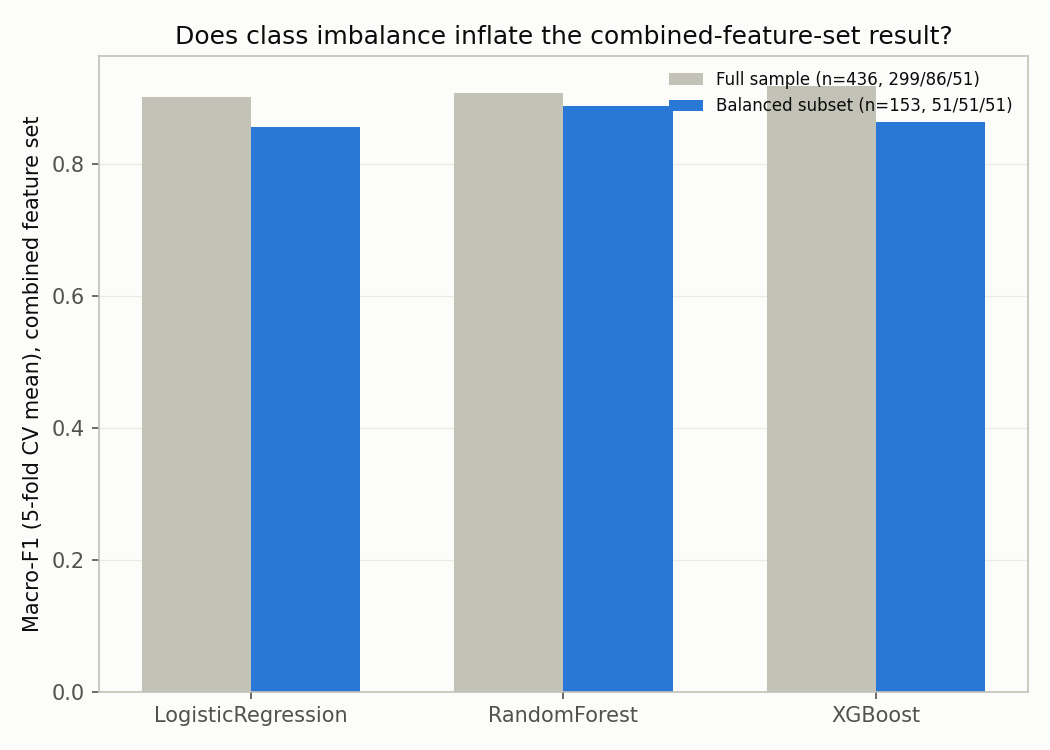

In [4]:
display(Image(filename=str(MODULE_DIR / "full_vs_balanced_comparison.png")))


## Interpretation

The balanced cohort tests the sensitivity of supervised estimates to the original class distribution. The fixed address list also supplies the matched cohort used by downstream GNN evaluations.

## Optional full rerun

Set `RUN_RETRAINING = True` in the setup cell and run all cells to recompute this stage. New artifacts are written to `rerun_validation/`, preserving the frozen dissertation evidence.

### Imports and helper functions

In [5]:
if RUN_RETRAINING:
    import sys
    sys.argv = [sys.argv[0]]
    import sys
    import json
    from pathlib import Path

    import numpy as np
    import pandas as pd
    import networkx as nx
    import matplotlib.pyplot as plt

    from sklearn.model_selection import StratifiedKFold
    from sklearn.linear_model import LogisticRegression
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler, LabelEncoder
    from sklearn.metrics import f1_score, balanced_accuracy_score
    from sklearn.utils.class_weight import compute_sample_weight
    from xgboost import XGBClassifier
    from scipy import stats


### 0. Setup

In [6]:
if RUN_RETRAINING:
    # Re-run the supervised comparisons on 51 addresses per class to measure
    # sensitivity to the 299/86/51 full-sample class distribution.

    RANDOM_STATE = 42
    N_SPLITS = 5
    LABEL_COL = "label"
    LABEL_ORDER = ["CEX", "DeFi", "Malicious_MEV"]
    MODEL_ORDER = ["LogisticRegression", "RandomForest", "XGBoost"]
    MODEL_COLORS = {"LogisticRegression": "#2a78d6", "RandomForest": "#1baf7a", "XGBoost": "#eb6834"}

    # Optional CLI args: feat_file edges_file emb_dir out_subdir classification_dir.
    PROJECT_ROOT = ROOT
    FEATURE_DIR = PROJECT_ROOT / "02_feature_engineering" / "feature_engineering"
    FEAT_FILE = Path(sys.argv[1]) if len(sys.argv) > 1 else FEATURE_DIR / "seed_feature_matrix_reconstructed.csv"
    EDGES_FILE = Path(sys.argv[2]) if len(sys.argv) > 2 else PROJECT_ROOT / "00_data_graph" / "data" / "main" / "raw_edges_reconstructed.csv"
    EMB_DIR = Path(sys.argv[3]) if len(sys.argv) > 3 else PROJECT_ROOT / "03_unsupervised" / "node2vec_results"
    OUT_SUBDIR = Path(sys.argv[4]) if len(sys.argv) > 4 else RERUN_DIR
    CLASSIFICATION_DIR = (
        Path(sys.argv[5])
        if len(sys.argv) > 5
        else PROJECT_ROOT / "04_supervised" / "01_traditional_ml" / "classification_cv_results"
    )
    FEATURE_GROUPS_FILE = FEATURE_DIR / "feature_groups.json"

    OUT_DIR = Path(OUT_SUBDIR)
    OUT_DIR.mkdir(parents=True, exist_ok=True)

    plt.rcParams.update({
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": "#0b0b0b",
        "text.color": "#0b0b0b",
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "grid.color": "#e1e0d9",
        "font.size": 10,
    })


    def clean_address(x):
        if pd.isna(x):
            return np.nan
        return str(x).strip().lower()


    def run_cv(feature_sets, y, group_label):
        """5-fold stratified CV for every (feature_set_name, model) pair. Returns
        a long-format fold-score DataFrame."""
        label_encoder = LabelEncoder().fit(LABEL_ORDER)
        rows = []
        for fs_name, X in feature_sets.items():
            for model_name in MODEL_ORDER:
                skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
                for fold_i, (train_idx, test_idx) in enumerate(skf.split(X, y)):
                    X_train, X_test = X[train_idx], X[test_idx]
                    y_train, y_test = y[train_idx], y[test_idx]

                    if model_name == "LogisticRegression":
                        model = Pipeline([
                            ("scaler", StandardScaler()),
                            ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
                        ])
                        model.fit(X_train, y_train)
                        y_pred = model.predict(X_test)
                    elif model_name == "RandomForest":
                        model = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
                        model.fit(X_train, y_train)
                        y_pred = model.predict(X_test)
                    else:
                        model = XGBClassifier(n_estimators=300, random_state=RANDOM_STATE, eval_metric="mlogloss", n_jobs=-1)
                        y_train_enc = label_encoder.transform(y_train)
                        sample_weight = compute_sample_weight("balanced", y_train_enc)
                        model.fit(X_train, y_train_enc, sample_weight=sample_weight)
                        y_pred = label_encoder.inverse_transform(model.predict(X_test))

                    rows.append({
                        "group": group_label, "feature_set": fs_name, "model": model_name, "fold": fold_i,
                        "macro_f1": f1_score(y_test, y_pred, average="macro"),
                        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
                    })
        return pd.DataFrame(rows)


    def paired_tests(fold_df, pairs, group_label):
        rows = []
        for a_name, b_name in pairs:
            for model_name in MODEL_ORDER:
                a = fold_df[(fold_df.group == group_label) & (fold_df.feature_set == a_name) & (fold_df.model == model_name)].sort_values("fold")["macro_f1"].values
                b = fold_df[(fold_df.group == group_label) & (fold_df.feature_set == b_name) & (fold_df.model == model_name)].sort_values("fold")["macro_f1"].values
                diff = a - b
                t_stat, p_val = stats.ttest_rel(a, b)
                rows.append({
                    "group": group_label, "comparison": f"{a_name} vs {b_name}", "model": model_name,
                    "mean_diff": diff.mean(), "paired_t_stat": t_stat, "paired_p_value": p_val,
                    "n_folds_improved": int((diff > 0).sum()),
                })
        return pd.DataFrame(rows)


### 1. Load hand-crafted features, feature groups, pagerank rank transform

In [7]:
if RUN_RETRAINING:
    # Identical construction to 01_classification.ipynb / feature_ablation_shap.ipynb so
    # the balanced-subset numbers are directly comparable to the full-sample ones.

    feat = pd.read_csv(FEAT_FILE)
    with open(FEATURE_GROUPS_FILE) as f:
        feature_groups = json.load(f)

    txn_cols = list(feature_groups["transaction_behaviour"])
    struct_cols = list(feature_groups["graph_structural"])

    edges = pd.read_csv(EDGES_FILE)
    edges["source"] = edges["source"].apply(clean_address)
    edges["target"] = edges["target"].apply(clean_address)
    edges = edges.dropna(subset=["source", "target"])

    G_directed = nx.from_pandas_edgelist(edges, source="source", target="target", edge_attr=["tx_count"], create_using=nx.DiGraph())
    pagerank_rank = pd.Series(nx.pagerank(G_directed)).rank(pct=True)
    pagerank_weighted_rank = pd.Series(nx.pagerank(G_directed, weight="tx_count")).rank(pct=True)

    feat["pagerank_rank"] = feat["address"].map(pagerank_rank).fillna(0.0)
    feat["pagerank_weighted_rank"] = feat["address"].map(pagerank_weighted_rank).fillna(0.0)

    for col in ["pagerank", "pagerank_weighted", "log_pagerank", "log_pagerank_weighted"]:
        if col in struct_cols:
            struct_cols.remove(col)
    struct_cols += ["pagerank_rank", "pagerank_weighted_rank"]

    handcrafted_cols = txn_cols + struct_cols


### 2. Build the balanced subset: 51 seeds per class (CEX = smallest active class)

In [8]:
if RUN_RETRAINING:

    active = feat[feat["is_active"]].copy()
    emb = pd.read_csv(f"{EMB_DIR}/seed_node2vec_embeddings.csv")
    emb_cols = [c for c in emb.columns if c.startswith("emb_")]
    data_full = active.merge(emb[["address"] + emb_cols], on="address", how="inner")

    n_per_class = data_full[LABEL_COL].value_counts().min()
    print(f"Full active-labelled sample: {dict(data_full[LABEL_COL].value_counts())}")
    print(f"Balanced subset target: {n_per_class} seeds per class (= smallest class size)")

    balanced = pd.concat(
        [
            group.sample(n=n_per_class, random_state=RANDOM_STATE)
            for _, group in data_full.groupby(LABEL_COL)
        ],
        ignore_index=True,
    )
    balanced.to_csv(OUT_DIR / "balanced_subset_seeds.csv", index=False)
    print(f"Balanced subset: {len(balanced)} seeds, {dict(balanced[LABEL_COL].value_counts())}")
    print(f"Saved seed list to {OUT_DIR / 'balanced_subset_seeds.csv'}")

    y_bal = balanced[LABEL_COL].to_numpy()
    X_hand_bal = balanced[handcrafted_cols].to_numpy(dtype=float)
    X_emb_bal = balanced[emb_cols].to_numpy(dtype=float)
    X_combined_bal = np.hstack([X_hand_bal, X_emb_bal])
    X_txn_bal = balanced[txn_cols].to_numpy(dtype=float)
    X_struct_bal = balanced[struct_cols].to_numpy(dtype=float)


### 3. Main classification robustness: hand_crafted vs embedding vs combined, on balanced subset

In [9]:
if RUN_RETRAINING:

    week8_sets = {"hand_crafted": X_hand_bal, "embedding": X_emb_bal, "combined": X_combined_bal}
    fold_df_w8 = run_cv(week8_sets, y_bal, group_label="week8_embedding")

    week8_summary = (
        fold_df_w8.groupby(["feature_set", "model"])[["macro_f1", "balanced_accuracy"]]
        .agg(["mean", "std"])
    )
    week8_summary.columns = ["_".join(c) for c in week8_summary.columns]
    week8_summary = week8_summary.reset_index().round(4)
    print(f"\n=== [Balanced subset] main classification comparison: hand_crafted / embedding / combined ===")
    print(week8_summary.to_string(index=False))

    week8_paired = paired_tests(fold_df_w8, [("combined", "hand_crafted")], "week8_embedding")
    print(f"\n=== [Balanced subset] Paired test: combined vs hand_crafted ===")
    print(week8_paired.round(4).to_string(index=False))


### 4. Feature-group robustness: transaction_behaviour vs graph_structural vs combined

In [10]:
if RUN_RETRAINING:

    week9_sets = {"transaction_behaviour": X_txn_bal, "graph_structural": X_struct_bal, "combined": X_hand_bal}
    fold_df_w9 = run_cv(week9_sets, y_bal, group_label="week9_ablation")

    week9_summary = (
        fold_df_w9.groupby(["feature_set", "model"])[["macro_f1", "balanced_accuracy"]]
        .agg(["mean", "std"])
    )
    week9_summary.columns = ["_".join(c) for c in week9_summary.columns]
    week9_summary = week9_summary.reset_index().round(4)
    print(f"\n=== [Balanced subset] feature-group ablation: transaction_behaviour / graph_structural / combined ===")
    print(week9_summary.to_string(index=False))

    week9_paired = paired_tests(fold_df_w9, [("combined", "transaction_behaviour"), ("combined", "graph_structural")], "week9_ablation")
    print(f"\n=== [Balanced subset] Paired tests: combined vs single group ===")
    print(week9_paired.round(4).to_string(index=False))

    # Save everything
    fold_all = pd.concat([fold_df_w8, fold_df_w9], ignore_index=True)
    fold_all.to_csv(OUT_DIR / "balanced_cv_fold_scores.csv", index=False)

    summary_all = pd.concat([
        week8_summary.assign(group="week8_embedding"),
        week9_summary.assign(group="week9_ablation"),
    ], ignore_index=True)
    summary_all.to_csv(OUT_DIR / "balanced_summary.csv", index=False)

    paired_all = pd.concat([week8_paired, week9_paired], ignore_index=True)
    paired_all.round(4).to_csv(OUT_DIR / "balanced_paired_test.csv", index=False)
    print(f"\nSaved {OUT_DIR / 'balanced_cv_fold_scores.csv'}, 'balanced_summary.csv', 'balanced_paired_test.csv'")


### 5. Side-by-side comparison chart: full sample vs balanced subset (combined feature set)

In [11]:
if RUN_RETRAINING:

    full_summary = pd.read_csv(f"{CLASSIFICATION_DIR}/classification_summary.csv")
    full_combined = full_summary[full_summary.feature_set == "combined"].set_index("model")["macro_f1_mean"]
    bal_combined = week8_summary[week8_summary.feature_set == "combined"].set_index("model")["macro_f1_mean"]

    fig, ax = plt.subplots(figsize=(7, 5))
    x = np.arange(len(MODEL_ORDER))
    width = 0.35
    ax.bar(x - width / 2, [full_combined.get(m, np.nan) for m in MODEL_ORDER], width, color="#c3c2b7", label="Full sample (n=436, 299/86/51)")
    ax.bar(x + width / 2, [bal_combined.get(m, np.nan) for m in MODEL_ORDER], width, color="#2a78d6", label=f"Balanced subset (n={len(balanced)}, {n_per_class}/{n_per_class}/{n_per_class})")
    ax.set_xticks(x)
    ax.set_xticklabels(MODEL_ORDER)
    ax.set_ylabel("Macro-F1 (5-fold CV mean), combined feature set")
    ax.set_title("Does class imbalance inflate the combined-feature-set result?")
    ax.legend(frameon=False, fontsize=8)
    ax.grid(axis="y", linewidth=0.6, alpha=0.6)
    ax.set_axisbelow(True)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "full_vs_balanced_comparison.png", dpi=150)
    plt.close(fig)
    print(f"Saved {OUT_DIR / 'full_vs_balanced_comparison.png'}")

    # =========================

    print(f"Balanced-subset rerun outputs: {OUT_DIR}")
